# Step 7. Model Evaluation & Validation

**Вопрос:** чем Moneyball AI отличается от rating-baseline при одинаковом бюджете и даёт ли это полезные последующие результаты?

Проверки: K-Means silhouette и refit-ARI; KNN cosine **и различия уровня** (RMS), устойчивость TOP-5; регрессия MAE/RMSE/R²; сравнение кандидатов по стоимости, качествам и алгоритмическому профилю. Наконец — последующее изменение записанной стоимости из датированной истории Transfermarkt, **не использованной для fit или выбора рекомендаций**.

Не подменяем эффективность оптимизируемым сходством. Последующая стоимость — дополнительный экономический proxy, не доход от реального трансфера и не спортивная результативность. Это ретроспективный исследовательский backtest: test уже изучался в EDA, а группы не рандомизированы.

**Срез:** 26.09.2022; **горизонт:** 26.09.2023. Основной бюджет 15 млн на одного альтернативного кандидата, возраст ≤30, TOP-5. EUR — допущение сценария; валюта TM не сертифицирована. Для таблиц используем исходные единицы. Основные запросы — 41 test-референс с исходной стоимостью >15 млн; все 578 test-запросов — дополнительное описание.

Протокол фиксируется до присоединения outcomes в этом запуске; это не внешняя пререгистрация исследования. Когорта ограничена успешно сопоставленными CM с валидной исходной оценкой.

Модель регрессии остаётся в `07_market_value_prediction.ipynb`; этот notebook — отдельный deliverable оценки, с запрошенным именем.


In [1]:
from pathlib import Path
import os
os.environ["LOKY_MAX_CPU_COUNT"]="1"
import sys,json,hashlib,zipfile
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import silhouette_score,adjusted_rand_score,mean_absolute_error,mean_squared_error,r2_score
from sklearn.dummy import DummyRegressor
from IPython.display import display,Markdown
from threadpoolctl import threadpool_limits
%matplotlib inline
_limits=threadpool_limits(1)
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/"config/feature_set_v1.json").exists())
sys.path.insert(0,str(ROOT))
from src.models import PlayerModels,CORE_FEATURES,FEATURE_GROUPS,eligible_ids_hash
from src.baseline import build_eligible_pool,select_baseline
from src.valuation import VALUE_FEATURES,make_ridge_estimator
from src.evaluation import dated_value_outcomes,paired_list_outcomes
OUT=ROOT/"data/processed/evaluation";REPORT=ROOT/"reports/evaluation"
OUT.mkdir(parents=True,exist_ok=True);REPORT.mkdir(parents=True,exist_ok=True)
SEED=42;CUTOFF="2022-09-26";BUDGET=15_000_000;MAX_AGE=30;TOP_K=5;REFERENCE_ID="182521"
CORE=list(CORE_FEATURES);figures=[]
def sha(p):
    h=hashlib.sha256()
    with Path(p).open("rb") as f:
        for chunk in iter(lambda:f.read(8*1024*1024),b""):h.update(chunk)
    return h.hexdigest()
def show(fig,name):
    for ext in ["png","svg"]:
        path=REPORT/f"{name}.{ext}";fig.savefig(path,dpi=150,bbox_inches="tight")
        if ext=="svg":path.write_text("\n".join(s.rstrip() for s in path.read_text(encoding="utf-8").splitlines())+"\n",encoding="utf-8")
    figures.append(name);plt.show();plt.close(fig)
plt.rcParams.update({"font.family":"DejaVu Sans","font.size":10,"figure.constrained_layout.use":True})
protocol={"cutoff":CUTOFF,"primary_budget":BUDGET,"candidate_max_age":MAX_AGE,"top_k":TOP_K,
          "query_population":"test; primary subset recorded value > 15m; never changed by follow-up",
          "candidate_gallery":"2308 training players only","recommendation":"frozen global KNN, no regression-gap reranking",
          "baseline":"overall descending, price then ID ascending; same eligible IDs",
          "future_horizon_days":365,"primary_max_future_quote_lag_days":120,
          "future_lag_sensitivity_days":[90,120,180],"baseline_quote_age_sensitivity_days":[120,365],
          "budget_sensitivity":[5_000_000,10_000_000,15_000_000,20_000_000],
          "future_endpoint":"mean log(followup value / recorded selection value), paired only if both fixed TOP-5 fully observed",
          "missing":"no zero imputation, no recommendation replacement; zero/conflicting quotes unavailable",
          "inference":"descriptive; no independent query-slot tests because candidates are reused",
          "currency":"unverified source units; EUR assumed for budget scenario","seed":SEED}
(REPORT/"evaluation_protocol.json").write_text(json.dumps(protocol,ensure_ascii=False,indent=2),encoding="utf-8")


Out[1]: 1094


## 1. Зафиксированные данные и обученные модели

Проверяем SHA-256 входа и обоих bundles. Не выбираем новые признаки, k или параметры RF по последующим результатам. Fit-игроки и test-референсы разделены по FIFA и TM ID. Исторические поля будущих оценок далее используются **только как outcomes**.


In [2]:
FD=ROOT/"data/processed/features"
fm=json.loads((FD/"feature_manifest.json").read_text(encoding="utf-8"))
ms=json.loads((ROOT/"reports/models/models_summary.json").read_text(encoding="utf-8"))
vs=json.loads((ROOT/"reports/valuation/valuation_summary.json").read_text(encoding="utf-8"))
source=FD/"moneyball_features_2022-09-26.csv"
assert sha(source)==fm["outputs"][source.name]["sha256"]==ms["input_sha256"]==vs["source_sha256"]
data=pd.read_csv(source,dtype={"fifa_id":"string","tm_id":"string","league_id":"string"})
train=data.loc[data.split.eq("train")].sort_values("fifa_id").reset_index(drop=True)
test=data.loc[data.split.eq("test")].sort_values("fifa_id").reset_index(drop=True)
assert (len(train),len(test))==(2308,578)
assert data.fifa_id.is_unique and data.tm_id.is_unique
assert not set(train.fifa_id)&set(test.fifa_id) and not set(train.tm_id)&set(test.tm_id)
mp=ROOT/"data/processed/models"/ms["model_bundle"]
vp=ROOT/"data/processed/valuation/market_value_rf_2022-09-26.joblib"
assert sha(mp)==ms["model_sha256"] and sha(vp)==vs["model_sha256"]
model=joblib.load(mp);regressor=joblib.load(vp)  # own verified local bundles only
assert set(model.train_ids_)==set(regressor.train_ids_)==set(train.fifa_id)
assert set(model.gallery_.fifa_id)==set(train.fifa_id)
assert list(model.feature_names_in_)==CORE and list(regressor.feature_names_in_)==list(VALUE_FEATURES)
assert data.as_of_date.eq(CUTOFF).all() and data.fifa_update_date.eq(CUTOFF).all()
assert data.market_value_date.le(CUTOFF).all()
primary_ids=set(test.loc[test.tm_market_value.gt(BUDGET),"fifa_id"])
assert len(primary_ids)==41
display(pd.DataFrame({"population":["train gallery","all test references","primary expensive references"],"players":[len(train),len(test),len(primary_ids)]}))


,population,players
0,train gallery,2308
1,all test references,578
2,primary expensive references,41


## 2. Baseline vs Moneyball AI: одинаковая допустимая галерея

В обоих методах exact CM, тот же бюджет, возраст ≤30 и historical-value policy. Референсы отсутствуют в train-галерее; self-match невозможен. Baseline ранжирует overall, KNN — cosine по 18 игровым признакам. Цена и возраст не входят в геометрию KNN. Записываем списки и их hash **до чтения будущих outcomes**.

Сходство — внутренний критерий. RMS по z-score показывает разницу абсолютного игрового уровня: высокий cosine не гарантирует полноценной замены. Cluster 0…2 — алгоритмические профили, не доказанные футбольные роли. Общая стоимость пяти альтернатив не сравнивается с бюджетом одного приобретения.


returned    mean_value  ...  mean_rms_z  strong_fraction
primary_reference method                            ...                             
False             baseline       5.0  1.420000e+07  ...      1.8334           0.0127
                  knn            5.0  2.576462e+06  ...      0.6178           0.2276
True              baseline       5.0  1.420000e+07  ...      0.9791           0.2146
                  knn            5.0  7.827561e+06  ...      0.6616           0.6000

[4 rows x 7 columns]

**Тони Кроос: два списка при одном бюджете 15 млн, возраст ≤30:**

,baseline_short_name,baseline_tm_market_value,baseline_overall,baseline_age_at_cutoff,baseline_similarity,baseline_rms_z,baseline_cluster,knn_short_name,knn_tm_market_value,knn_overall,knn_age_at_cutoff,knn_similarity,knn_rms_z,knn_cluster
1,Sergi Darder,14000000.0,82,28.762,0.845,1.329,1,Campaña,5000000.0,78,29.323,0.949,1.042,2
2,E. Can,14000000.0,82,28.704,0.810,1.433,2,Y. Adli,9000000.0,75,22.161,0.937,1.280,2
3,R. Andrich,13000000.0,81,28.012,0.796,1.394,2,J. Veerman,14000000.0,78,23.853,0.929,1.083,2
4,K. Demirbay,15000000.0,81,29.233,0.909,1.067,2,É. Gutiérrez,7000000.0,76,27.283,0.924,1.308,2
5,C. Tolisso,15000000.0,81,28.148,0.906,1.082,2,S. Longstaff,15000000.0,74,24.907,0.922,1.328,2


,feature,reference,baseline_mean,knn_mean
0,attacking_short_passing,93.0,82.2,79.0
1,skill_long_passing,93.0,82.8,78.2
2,mentality_vision,89.0,80.0,79.4
3,skill_ball_control,88.0,81.4,77.8
4,skill_dribbling,80.0,80.2,76.2
5,movement_agility,63.0,73.2,69.4
6,movement_balance,71.0,73.0,69.6
7,movement_reactions,90.0,80.2,74.8
8,mentality_composure,88.0,77.8,76.8
9,power_stamina,75.0,82.4,78.4


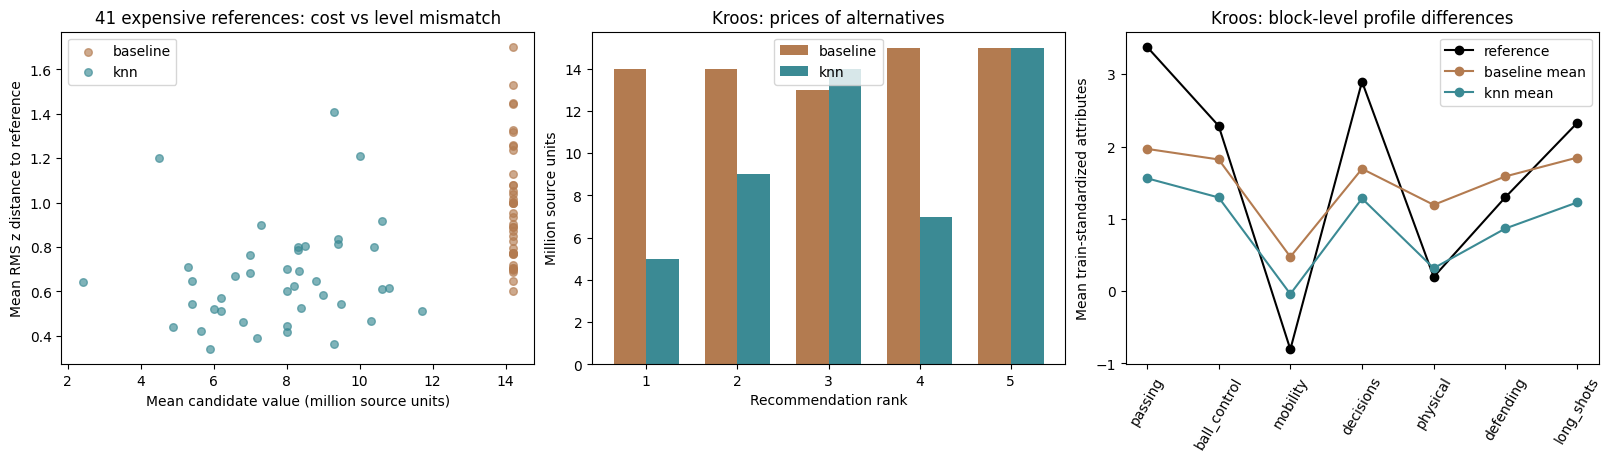

In [3]:
candidate_pos={pid:i for i,pid in enumerate(train.fifa_id)}
Ztrain=model.scaler_.transform(train[CORE]);Ztest=model.scaler_.transform(test[CORE])
Wtrain=model.transform(train);Wtest=model.transform(test)
labels=dict(zip(model.gallery_.fifa_id,model.gallery_clusters_))
list_parts=[];audit_parts=[];expected_pool_hashes={}
for budget in protocol["budget_sensitivity"]:
    knn,audit=model.recommend_many(test,max_value=budget,max_age=MAX_AGE,top_k=TOP_K)
    pool,_=build_eligible_pool(train,max_value=budget,max_age=MAX_AGE,cutoff=CUTOFF)
    assert audit.eligible_ids_sha256.eq(eligible_ids_hash(pool.fifa_id)).all()
    expected_pool_hashes[budget]=eligible_ids_hash(pool.fifa_id)
    baseline=select_baseline(pool,max_value=budget,max_age=MAX_AGE,top_k=TOP_K,cutoff=CUTOFF)
    assert len(baseline)==TOP_K and audit.returned.eq(TOP_K).all()
    bpos=np.array([candidate_pos[pid] for pid in baseline.fifa_id])
    parts=[]
    for i,q in test.iterrows():
        part=baseline.copy();part["reference_id"]=q.fifa_id;part["rank"]=part.baseline_rank
        b=Wtrain[bpos];a=Wtest[i]
        part["similarity"]=(b@a)/(np.linalg.norm(b,axis=1)*np.linalg.norm(a))
        part["rms_z"]=np.sqrt(np.mean((Ztrain[bpos]-Ztest[i])**2,axis=1))
        part["cluster"]=part.fifa_id.map(labels)
        part["strong_profile_match"]=part.similarity.ge(.90)&part.rms_z.le(.75)
        parts.append(part)
    base=pd.concat(parts,ignore_index=True);base["method"]="baseline"
    knn["method"]="knn";knn["rank"]=knn.model_rank
    both=pd.concat([base,knn],ignore_index=True);both["budget"]=budget
    both["primary_reference"]=both.reference_id.isin(primary_ids)
    assert not both.fifa_id.eq(both.reference_id).any() and both.tm_market_value.le(budget).all()
    assert both.age_at_cutoff.le(MAX_AGE).all() and not both.duplicated(["reference_id","method","fifa_id"]).any()
    list_parts.append(both);audit["budget"]=budget;audit_parts.append(audit)
lists=pd.concat(list_parts,ignore_index=True)
lists.to_csv(OUT/"frozen_recommendations_all_budgets.csv",index=False)
pd.concat(audit_parts).to_csv(OUT/"eligible_pool_audit.csv",index=False)
list_hash=sha(OUT/"frozen_recommendations_all_budgets.csv")
protocol["frozen_recommendations_sha256"]=list_hash
(REPORT/"evaluation_protocol.json").write_text(json.dumps(protocol,ensure_ascii=False,indent=2),encoding="utf-8")
main=lists.loc[lists.budget.eq(BUDGET)].copy()
quality=lists.groupby(["budget","reference_id","method","primary_reference"]).agg(
    returned=("fifa_id","size"),mean_value=("tm_market_value","mean"),mean_age=("age_at_cutoff","mean"),
    mean_overall=("overall","mean"),mean_cosine=("similarity","mean"),mean_rms_z=("rms_z","mean"),
    strong_fraction=("strong_profile_match","mean")).reset_index()
quality.to_csv(OUT/"per_reference_quality.csv",index=False)
internal=quality.loc[quality.budget.eq(BUDGET)].groupby(["primary_reference","method"]).mean(numeric_only=True).drop(columns="budget")
internal.to_csv(REPORT/"internal_recommendation_comparison.csv")
display(internal.round(4))
case=main.loc[main.reference_id.eq(REFERENCE_ID)].copy()
side=[]
for method in ["baseline","knn"]:
    p=case.loc[case.method.eq(method)].sort_values("rank")
    side.append(p[["short_name","tm_market_value","overall","age_at_cutoff","similarity","rms_z","cluster"]].reset_index(drop=True).add_prefix(method+"_"))
comparison=pd.concat(side,axis=1);comparison.index=np.arange(1,TOP_K+1)
comparison.to_csv(OUT/"kroos_side_by_side.csv",index_label="rank")
display(Markdown("**Тони Кроос: два списка при одном бюджете 15 млн, возраст ≤30:**"));display(comparison.round(3))
reference=test.loc[test.fifa_id.eq(REFERENCE_ID)].iloc[0]
case_profiles=pd.DataFrame({"feature":CORE,"reference":reference[CORE].to_numpy(float),
                            "baseline_mean":case.loc[case.method.eq("baseline"),CORE].mean().to_numpy(),
                            "knn_mean":case.loc[case.method.eq("knn"),CORE].mean().to_numpy()})
case_profiles.to_csv(REPORT/"kroos_raw_attribute_comparison.csv",index=False);display(case_profiles.round(2))
fig,axes=plt.subplots(1,3,figsize=(16,4.5))
for method,color in [("baseline","#b37b50"),("knn","#3b8a94")]:
    q=quality.loc[quality.budget.eq(BUDGET)&quality.primary_reference&quality.method.eq(method)]
    axes[0].scatter(q.mean_value/1e6,q.mean_rms_z,alpha=.65,s=30,label=method,color=color)
    p=case.loc[case.method.eq(method)]
    positions=np.arange(5)+(-.18 if method=="baseline" else .18)
    axes[1].bar(positions,p.tm_market_value/1e6,width=.36,label=method,color=color)
axes[0].set(xlabel="Mean candidate value (million source units)",ylabel="Mean RMS z distance to reference",title="41 expensive references: cost vs level mismatch");axes[0].legend()
axes[1].set(xticks=np.arange(5),xticklabels=np.arange(1,6),xlabel="Recommendation rank",ylabel="Million source units",title="Kroos: prices of alternatives");axes[1].legend()
for name,raw,color in [("reference",reference[CORE].to_numpy(float),"black"),
                       ("baseline mean",case.loc[case.method.eq("baseline"),CORE].mean().to_numpy(),"#b37b50"),
                       ("knn mean",case.loc[case.method.eq("knn"),CORE].mean().to_numpy(),"#3b8a94")]:
    z=(raw-model.scaler_.mean_)/model.scaler_.scale_
    axes[2].plot(np.arange(len(FEATURE_GROUPS)),[z[[CORE.index(f) for f in fs]].mean() for fs in FEATURE_GROUPS.values()],"o-",label=name,color=color)
axes[2].set(xticks=np.arange(len(FEATURE_GROUPS)),xticklabels=list(FEATURE_GROUPS),ylabel="Mean train-standardized attributes",title="Kroos: block-level profile differences")
axes[2].tick_params(axis="x",rotation=60);axes[2].legend()
show(fig,"01_baseline_vs_knn")


## 3. K-Means: разделение, refit-устойчивость, профили списков

k=3 уже выбран в Step 6 на train; не меняем его здесь. Silhouette рассчитываем по той же выборке train (1000, seed 42) и всему test. В 20 повторах fit всей обработки на 80% train; ARI сравнивает назначения исходного train. Высокая устойчивость при низком silhouette не доказывает чёткие естественные роли.


k                          3.000000
train_sample_silhouette    0.169609
test_silhouette            0.168940
refit_ari_median           0.862635
refit_ari_p05              0.752818
refit_ari_p95              0.936128
dtype: float64

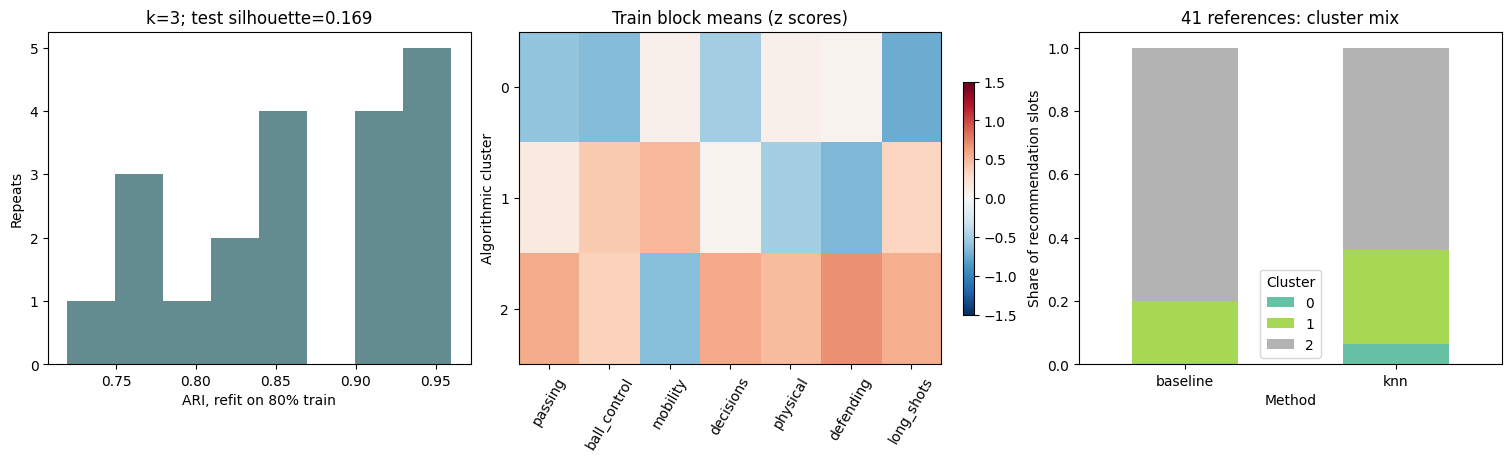

In [4]:
train_labels=model.predict_clusters(train);test_labels=model.predict_clusters(test)
sample=np.random.default_rng(SEED).choice(len(train),min(1000,len(train)),replace=False)
sil_train=float(silhouette_score(model.cluster_vectors(train)[sample],train_labels[sample]))
sil_test=float(silhouette_score(model.cluster_vectors(test),test_labels))
stability=[]
for repeat in range(20):
    ids=np.random.default_rng(SEED+repeat).choice(len(train),int(.8*len(train)),replace=False)
    fit=PlayerModels(n_clusters=model.n_clusters,random_state=SEED+repeat+1,n_init=10,cutoff=CUTOFF).fit(train.iloc[ids],gallery=train)
    stability.append(float(adjusted_rand_score(train_labels,fit.predict_clusters(train))))
clusters={"k":model.n_clusters,"train_sample_silhouette":sil_train,"test_silhouette":sil_test,
          "refit_ari_median":float(np.median(stability)),"refit_ari_p05":float(np.quantile(stability,.05)),"refit_ari_p95":float(np.quantile(stability,.95))}
display(pd.Series(clusters));pd.DataFrame({"repeat":np.arange(20),"ARI":stability}).to_csv(REPORT/"cluster_refit_stability.csv",index=False)
blocks=pd.DataFrame({g:Ztrain[:,[CORE.index(f) for f in fs]].mean(axis=1) for g,fs in FEATURE_GROUPS.items()})
blocks["cluster"]=train_labels
centers=blocks.groupby("cluster").mean();centers.to_csv(REPORT/"cluster_block_profiles.csv")
role_share=main.loc[main.primary_reference].groupby(["method","cluster"]).size().unstack(fill_value=0)
role_share=role_share.div(role_share.sum(axis=1),axis=0)
role_share.to_csv(REPORT/"primary_list_cluster_shares.csv")
fig,axes=plt.subplots(1,3,figsize=(15,4.5))
axes[0].hist(stability,bins=8,color="#638c90");axes[0].set(xlabel="ARI, refit on 80% train",ylabel="Repeats",title=f"k={model.n_clusters}; test silhouette={sil_test:.3f}")
im=axes[1].imshow(centers,aspect="auto",cmap="RdBu_r",vmin=-1.5,vmax=1.5)
axes[1].set(xticks=np.arange(len(FEATURE_GROUPS)),xticklabels=list(FEATURE_GROUPS),yticks=np.arange(model.n_clusters),ylabel="Algorithmic cluster",title="Train block means (z scores)")
axes[1].tick_params(axis="x",rotation=60);fig.colorbar(im,ax=axes[1],shrink=.7)
role_share.plot.bar(stacked=True,ax=axes[2],rot=0,colormap="Set2")
axes[2].set(ylabel="Share of recommendation slots",xlabel="Method",title="41 references: cluster mix");axes[2].legend(title="Cluster")
show(fig,"02_clusters_and_roles")


## 4. KNN: TOP-5 и чувствительность игровых входов

Фиксированная галерея и preprocessing. Добавляем независимый нормальный шум σ=1 или 2 рейтинговых пункта **к query-профилю**, с ограничением [1,99]. Все 41 дорогой референс + 9 других test-профилей, 10 повторов каждого уровня шума. Это overlap относительно исходного TOP-5; не доверительный интервал. Изменение самой галереи/сезона этим тестом не покрыто. Rating-baseline не зависит от query-атрибутов и в таком тесте сохраняет список полностью.


mean  median  min  max
sigma primary_reference                            
1.0   False              0.822222     0.8  0.4  1.0
      True               0.840976     0.8  0.2  1.0
2.0   False              0.695556     0.8  0.0  1.0
      True               0.721951     0.8  0.0  1.0

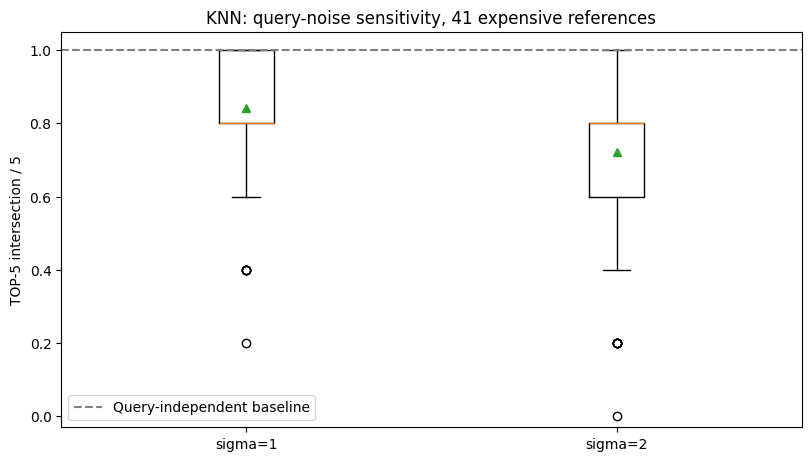

In [5]:
others=test.loc[~test.fifa_id.isin(primary_ids)].sample(n=9,random_state=SEED)
probes=pd.concat([test.loc[test.fifa_id.isin(primary_ids)],others]).reset_index(drop=True)
original={rid:set(p.fifa_id) for rid,p in main.loc[main.method.eq("knn")].groupby("reference_id")}
noise=[]
for sigma in [1.,2.]:
    for repeat in range(10):
        noisy=probes.copy();rng=np.random.default_rng(SEED+repeat)
        noisy[CORE]=np.clip(noisy[CORE].to_numpy(float)+rng.normal(0,sigma,(len(noisy),len(CORE))),1,99)
        rec,_=model.recommend_many(noisy,max_value=BUDGET,max_age=MAX_AGE,top_k=TOP_K)
        for rid,p in rec.groupby("reference_id"):
            noise.append({"sigma":sigma,"repeat":repeat,"reference_id":rid,"primary_reference":rid in primary_ids,
                          "overlap_at5":len(set(p.fifa_id)&original[rid])/TOP_K})
noise=pd.DataFrame(noise);noise.to_csv(OUT/"query_noise_trials.csv",index=False)
noise_summary=noise.groupby(["sigma","primary_reference"]).overlap_at5.agg(["mean","median","min","max"])
noise_summary.to_csv(REPORT/"knn_top5_stability.csv");display(noise_summary)
fig,ax=plt.subplots(figsize=(8,4.5))
arr=[noise.loc[noise.sigma.eq(s)&noise.primary_reference,"overlap_at5"].to_numpy() for s in [1.,2.]]
ax.boxplot(arr,tick_labels=["sigma=1","sigma=2"],showmeans=True)
ax.axhline(1,color="grey",ls="--",label="Query-independent baseline")
ax.set(ylim=(-.03,1.05),ylabel="TOP-5 intersection / 5",title="KNN: query-noise sensitivity, 41 expensive references");ax.legend()
show(fig,"03_knn_top5_stability")


## 5. Регрессия: MAE, RMSE, R²

RF bundle обучен только на train, параметры зафиксированы прежней CV. Восстанавливаем Ridge с ранее выбранным alpha, без нового подбора. Сравниваем одну и ту же test-выборку. Bootstrap 95% интервалы MAE/RMSE/R² условны на фиксированных моделях; R² в исходной и log-шкале — разные показатели. Эта модель оценивает **стоимость на дату отбора**, не будущую стоимость через год.


,MAE,RMSE,R2,MAE_log,R2_log
model,,,,,
Train median,3.284256e+06,7.901859e+06,-0.147163,1.273572,-0.020918
Ridge log,1.315547e+06,2.950272e+06,0.840084,0.508785,0.824076
Random Forest log,1.333985e+06,3.203745e+06,0.811426,0.486935,0.839225


MAE          RMSE        R2
model                                                        
Random Forest log 0.025  1.102377e+06  2.561791e+06  0.752714
                  0.975  1.573651e+06  3.799426e+06  0.861440
Ridge log         0.025  1.113654e+06  2.485811e+06  0.791688
                  0.975  1.534431e+06  3.402974e+06  0.875480
Train median      0.025  2.712391e+06  6.354992e+06 -0.185603
                  0.975  3.905479e+06  9.457722e+06 -0.115690

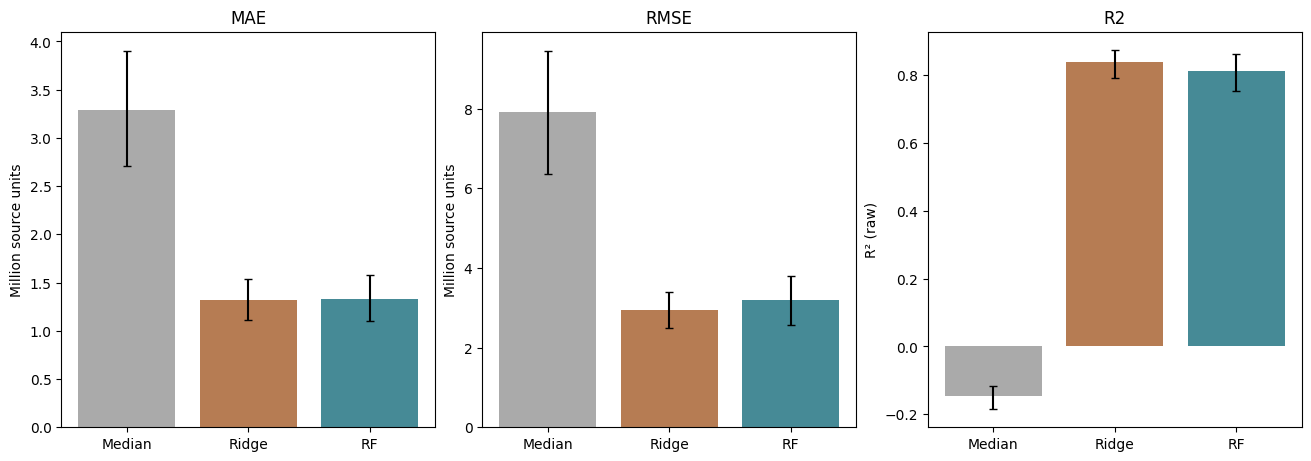

RF улучшает log-MAE, но Ridge имеет меньшие MAE/RMSE в исходной шкале. В Model 3 paired CI разности log-MAE включает ноль; убедительное превосходство RF не установлено.

In [6]:
ridge=make_ridge_estimator(alpha=vs["ridge_alpha"]).fit(train[list(VALUE_FEATURES)],train.tm_market_value)
y=test.tm_market_value.to_numpy(float)
preds={"Train median":np.full(len(test),train.tm_market_value.median()),"Ridge log":ridge.predict(test[list(VALUE_FEATURES)]),"Random Forest log":regressor.predict(test)}
def metrics(y,p):
    return {"MAE":float(mean_absolute_error(y,p)),"RMSE":float(np.sqrt(mean_squared_error(y,p))),"R2":float(r2_score(y,p)),
            "MAE_log":float(mean_absolute_error(np.log1p(y),np.log1p(p))),"R2_log":float(r2_score(np.log1p(y),np.log1p(p)))}
reg_metrics=pd.DataFrame({name:metrics(y,p) for name,p in preds.items()}).T.rename_axis("model")
assert np.isclose(reg_metrics.loc["Random Forest log","MAE"],vs["test_metrics"]["Random Forest log"]["MAE"])
reg_metrics.to_csv(REPORT/"regression_test_metrics.csv");display(reg_metrics)
rng=np.random.default_rng(SEED);boot=[]
for repeat in range(1000):
    indices=rng.integers(0,len(y),len(y))
    for name,p in preds.items():boot.append({"repeat":repeat,"model":name,**metrics(y[indices],p[indices])})
intervals=pd.DataFrame(boot).groupby("model")[["MAE","RMSE","R2"]].quantile([.025,.975])
intervals.to_csv(REPORT/"regression_bootstrap_intervals.csv");display(intervals)
fig,axes=plt.subplots(1,3,figsize=(13,4.5))
for ax,metric in zip(axes,["MAE","RMSE","R2"]):
    vals=reg_metrics[metric].to_numpy();lo=np.array([intervals.loc[(n,.025),metric] for n in reg_metrics.index]);hi=np.array([intervals.loc[(n,.975),metric] for n in reg_metrics.index])
    factor=1e6 if metric in ["MAE","RMSE"] else 1
    ax.bar(np.arange(3),vals/factor,yerr=[(vals-lo)/factor,(hi-vals)/factor],capsize=3,color=["#aaa","#b67c53","#468a96"])
    ax.set(xticks=np.arange(3),xticklabels=["Median","Ridge","RF"],title=metric,ylabel="Million source units" if factor>1 else "R² (raw)")
show(fig,"04_regression_validation")
display(Markdown("RF улучшает log-MAE, но Ridge имеет меньшие MAE/RMSE в исходной шкале. В Model 3 paired CI разности log-MAE включает ноль; убедительное превосходство RF не установлено."))


## 6. Доступны ли последующие независимые от fit данные?

Читаем `player_market_value.csv` непосредственно из проверенного ZIP. Берём последнюю оценку **≤26.09.2023**, не старше 120 дней и строго после отбора. Сезонные performance-агрегаты не используются в этой проверке: у них нет дат матчей, сезон 22/23 начинается до отбора, а сравнение разных лиг и минут требует отдельного дизайна. Не выдаём изменение стоимости за спортивную эффективность.

Горизонт 12 месяцев — дата проверки, а не гарантированный интервал между переоценками. Исходная цена может отставать от отбора на 365 дней; фактическое расстояние между двумя ценами сохраняется отдельно. Изменения не годовые и не annualized investment returns.

Точные дубликаты оценок схлопываются; противоречивые player/date карантинируют всё окно игрока; последняя нулевая оценка не заменяется более ранней положительной. Пропуски остаются пропусками. Зафиксированные рекомендации не заменяются игроками с доступным будущим.


In [7]:
archive=Path(os.environ.get("MONEYBALL_DATA_DIR",str(Path.home()/"Downloads")))/"xfkzujqjvx97n_football-datasets_data.zip"
assert sha(archive)==fm["source_sha256"]["transfermarkt"]
assert sha(OUT/"frozen_recommendations_all_budgets.csv")==list_hash
with zipfile.ZipFile(archive) as z:
    member=next(n for n in z.namelist() if n.endswith("/player_market_value.csv"))
    with z.open(member) as handle:history=pd.read_csv(handle,dtype={"player_id":"string"})
dates=pd.to_datetime(history.date_unix,format="%Y-%m-%d",errors="coerce")
history_audit={"rows":len(history),"min_date":str(dates.min().date()),"max_date":str(dates.max().date()),
               "rows_after_cutoff":int(dates.gt(pd.Timestamp(CUTOFF)).sum()),"invalid_dates":int(dates.isna().sum()),
               "zip_member":member,"archive_sha256":sha(archive)}
outcomes=dated_value_outcomes(data,history,cutoff=CUTOFF,horizon_days=365,max_lag_days=120)
observed=outcomes.loc[outcomes.outcome_observed]
assert observed.future_value_date.gt(pd.Timestamp(CUTOFF)).all()
assert observed.future_value_date.le(pd.Timestamp("2023-09-26")).all()
assert observed.future_quote_lag_days.between(0,120).all()
outcomes.to_csv(OUT/"future_value_outcomes_12m.csv",index=False)
coverage=outcomes.groupby("outcome_status").size().rename("players")
coverage.to_csv(REPORT/"future_outcome_status_counts.csv");display(pd.Series(history_audit));display(coverage)
timing=observed[["baseline_quote_age_days","future_quote_lag_days","quote_interval_days"]].describe(percentiles=[.05,.5,.95])
timing.to_csv(REPORT/"observed_quote_timing.csv");display(timing)
print("Frozen recommendation hash unchanged:",sha(OUT/"frozen_recommendations_all_budgets.csv")==list_hash)


Frozen recommendation hash unchanged: True


rows                                                            901429
min_date                                                    2003-12-14
max_date                                                    2025-09-11
rows_after_cutoff                                               252736
invalid_dates                                                        0
zip_member                 player_market_value/player_market_value.csv
archive_sha256       fb8481050cf6e246a6f4db9358a9c73b687ad6d17a08a7...
dtype: object

outcome_status
latest_quote_zero             39
no_valid_quote_in_window     152
observed                    2695
Name: players, dtype: int64

,baseline_quote_age_days,future_quote_lag_days,quote_interval_days
count,2695.000000,2695.000000,2695.000000
mean,95.936920,91.980705,368.956215
std,54.758277,27.895453,61.128234
min,0.000000,0.000000,258.000000
5%,7.000000,16.000000,265.000000
50%,105.000000,103.000000,371.000000
95%,168.000000,118.000000,483.000000
max,347.000000,120.000000,651.000000


## 7. Последующие результаты списков: покрытие и зависимости

Основной endpoint — средний `log(future_value / selection_value)` пяти кандидатов. Средняя доля изменения стоимости — дополнительная метрика; единичный рост дешёвого игрока может сильно влиять на неё. **Сравниваем только пары с полностью наблюдаемыми обоими TOP-5**, но показываем потери покрытия и доступность каждого слота. Это может внести selection bias.

Тот же игрок встречается у многих референсов; baseline часто повторяет одни и те же пять ID. Поэтому 41 запрос и 205 слотов не являются 205 независимыми исходами. Не рассчитываем p-value/CI, предполагающие независимость слотов или запросов. Приводим также число уникальных кандидатов и их распределение; это описательный backtest, без причинного вывода об эффекте трансфера.


,population,method,references,slots,observed_slots,unique_candidates,observed_unique_candidates,mean_log_ratio_unique_observed
0,primary_expensive,baseline,41,205,205,5,5,-0.203761
1,primary_expensive,knn,41,205,204,101,100,-0.025849
2,all_test,baseline,578,2890,2890,5,5,-0.203761
3,all_test,knn,578,2890,2766,1172,1117,0.105739


,population,references,complete_pairs,baseline_mean_log_ratio,knn_mean_log_ratio,mean_knn_minus_baseline_log_ratio,median_knn_minus_baseline_log_ratio,fraction_pairs_knn_higher
0,primary_expensive,41,40,-0.203761,-0.049864,0.153897,0.171748,0.82500
1,all_test,578,474,-0.203761,0.087101,0.290862,0.227526,0.85865


,population,complete_pairs,baseline_geometric_value_change_fraction,knn_geometric_value_change_fraction
0,primary_expensive,40,-0.184343,-0.048641
1,all_test,474,-0.184343,0.091007


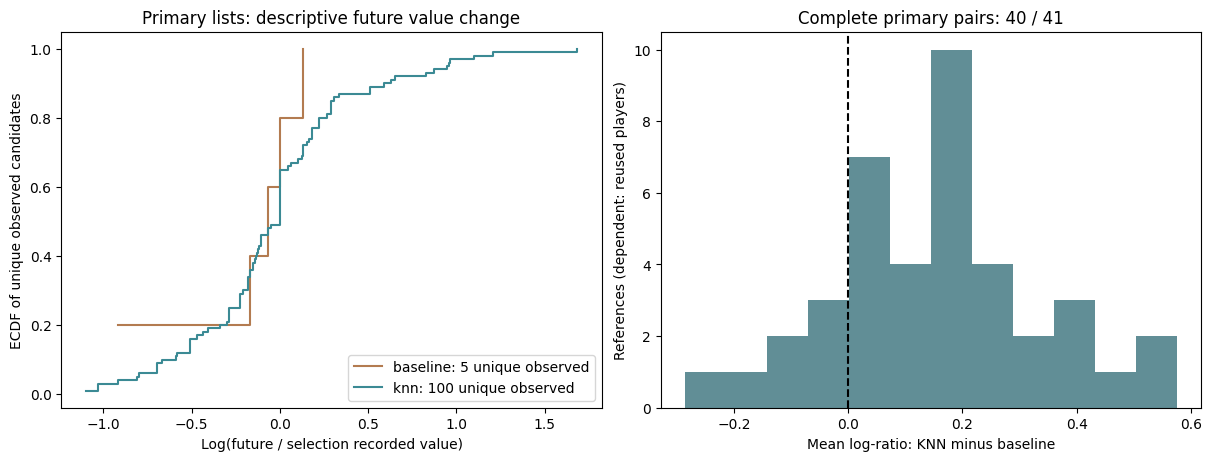

,method,rank,short_name,tm_market_value,market_value_date,future_value,future_value_date,outcome_status,value_change_fraction
65,baseline,1,Sergi Darder,14000000.0,2022-06-02,16000000.0,2023-06-12,observed,0.142857
66,baseline,2,E. Can,14000000.0,2022-09-20,14000000.0,2023-06-21,observed,0.000000
67,baseline,3,R. Andrich,13000000.0,2022-06-08,11000000.0,2023-06-21,observed,-0.153846
68,baseline,4,K. Demirbay,15000000.0,2022-06-08,6000000.0,2023-09-26,observed,-0.600000
69,baseline,5,C. Tolisso,15000000.0,2022-06-08,14000000.0,2023-06-26,observed,-0.066667
2955,knn,1,Campaña,5000000.0,2022-09-25,3000000.0,2023-06-13,observed,-0.400000
2956,knn,2,Y. Adli,9000000.0,2022-05-29,8000000.0,2023-06-14,observed,-0.111111
2957,knn,3,J. Veerman,14000000.0,2022-06-07,16000000.0,2023-06-22,observed,0.142857
2958,knn,4,É. Gutiérrez,7000000.0,2022-06-07,6000000.0,2023-06-22,observed,-0.142857
2959,knn,5,S. Longstaff,15000000.0,2022-09-14,25000000.0,2023-06-19,observed,0.666667


In [8]:
paired=paired_list_outcomes(main,outcomes,top_k=TOP_K)
paired["primary_reference"]=paired.reference_id.isin(primary_ids)
paired.to_csv(OUT/"paired_future_list_outcomes.csv",index=False)
joined=main.merge(outcomes[["fifa_id","outcome_status","outcome_observed","future_value","future_value_date","future_quote_lag_days","baseline_quote_age_days","quote_interval_days","value_change_fraction","log_value_ratio"]],on="fifa_id",validate="many_to_one")
joined.to_csv(OUT/"recommendations_with_future_outcomes.csv",index=False)
coverage_rows=[];result_rows=[]
for group,is_primary in [("primary_expensive",True),("all_test",False)]:
    group_lists=joined.loc[joined.primary_reference] if is_primary else joined
    group_paired=paired.loc[paired.primary_reference] if is_primary else paired
    complete=group_paired.loc[group_paired.complete_both]
    for method in ["baseline","knn"]:
        m=group_lists.loc[group_lists.method.eq(method)];unique=m.drop_duplicates("fifa_id")
        coverage_rows.append({"population":group,"method":method,"references":m.reference_id.nunique(),"slots":len(m),
                              "observed_slots":int(m.outcome_observed.sum()),"unique_candidates":m.fifa_id.nunique(),
                              "observed_unique_candidates":int(unique.outcome_observed.sum()),
                              "mean_log_ratio_unique_observed":float(unique.loc[unique.outcome_observed,"log_value_ratio"].mean())})
    result_rows.append({"population":group,"references":len(group_paired),"complete_pairs":len(complete),
                        "baseline_mean_log_ratio":float(complete.baseline_mean_log_value_ratio.mean()),
                        "knn_mean_log_ratio":float(complete.knn_mean_log_value_ratio.mean()),
                        "mean_knn_minus_baseline_log_ratio":float(complete.knn_minus_baseline_log_ratio.mean()),
                        "median_knn_minus_baseline_log_ratio":float(complete.knn_minus_baseline_log_ratio.median()),
                        "fraction_pairs_knn_higher":float(complete.knn_minus_baseline_log_ratio.gt(0).mean())})
coverage_table=pd.DataFrame(coverage_rows);future_results=pd.DataFrame(result_rows)
coverage_table.to_csv(REPORT/"future_list_coverage.csv",index=False)
future_results.to_csv(REPORT/"future_list_comparison.csv",index=False)
display(coverage_table);display(future_results)
geometric=future_results[["population","complete_pairs"]].copy()
geometric["baseline_geometric_value_change_fraction"]=np.expm1(future_results.baseline_mean_log_ratio)
geometric["knn_geometric_value_change_fraction"]=np.expm1(future_results.knn_mean_log_ratio)
geometric.to_csv(REPORT/"future_geometric_value_changes.csv",index=False);display(geometric)
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
primary=joined.loc[joined.primary_reference]
for method,color in [("baseline","#b37b50"),("knn","#3b8a94")]:
    u=primary.loc[primary.method.eq(method)].drop_duplicates("fifa_id")
    vals=np.sort(u.loc[u.outcome_observed,"log_value_ratio"].to_numpy())
    if len(vals):axes[0].step(vals,np.arange(1,len(vals)+1)/len(vals),where="post",label=f"{method}: {len(vals)} unique observed",color=color)
axes[0].set(xlabel="Log(future / selection recorded value)",ylabel="ECDF of unique observed candidates",title="Primary lists: descriptive future value change");axes[0].legend()
delta=paired.loc[paired.primary_reference&paired.complete_both,"knn_minus_baseline_log_ratio"]
axes[1].hist(delta,bins=12,color="#618e96");axes[1].axvline(0,color="black",ls="--")
axes[1].set(xlabel="Mean log-ratio: KNN minus baseline",ylabel="References (dependent: reused players)",title=f"Complete primary pairs: {len(delta)} / {len(primary_ids)}")
show(fig,"05_future_outcomes_and_coverage")
case_future=joined.loc[joined.reference_id.eq(REFERENCE_ID),["method","rank","short_name","tm_market_value","market_value_date","future_value","future_value_date","outcome_status","value_change_fraction"]]
case_future.to_csv(OUT/"kroos_future_outcomes.csv",index=False);display(case_future)


## 8. Предусмотренные проверки чувствительности

Окно будущей оценки: 90 / 120 / 180 дней; максимальный возраст исходной оценки: 120 / 365 дней. Меняются только критерии наблюдаемости исходов, **не состав списков**. Основной 120/365 результат сохраняется даже при более привлекательных альтернативных результатах. Более строгое окно может исключить все пары — это честный результат ограничения данных.

Бюджеты 5 / 10 / 15 / 20 млн: отдельные списки зафиксированы до чтения history, параметры модели неизменны. Те же 41 референс удерживаются во всех сценариях. Это sensitivity, не подбор наилучшего бюджета по будущим данным.


,future_max_lag_days,baseline_max_age_days,budget,complete_pairs,total_primary_references,mean_knn_minus_baseline_log_ratio,fraction_pairs_knn_higher
2,90,120,15000000,0,41,NaN,NaN
6,90,365,15000000,0,41,NaN,NaN
10,120,120,15000000,29,41,0.137802,0.758621
14,120,365,15000000,40,41,0.153897,0.825000
18,180,120,15000000,30,41,0.136805,0.766667
22,180,365,15000000,41,41,0.152775,0.829268


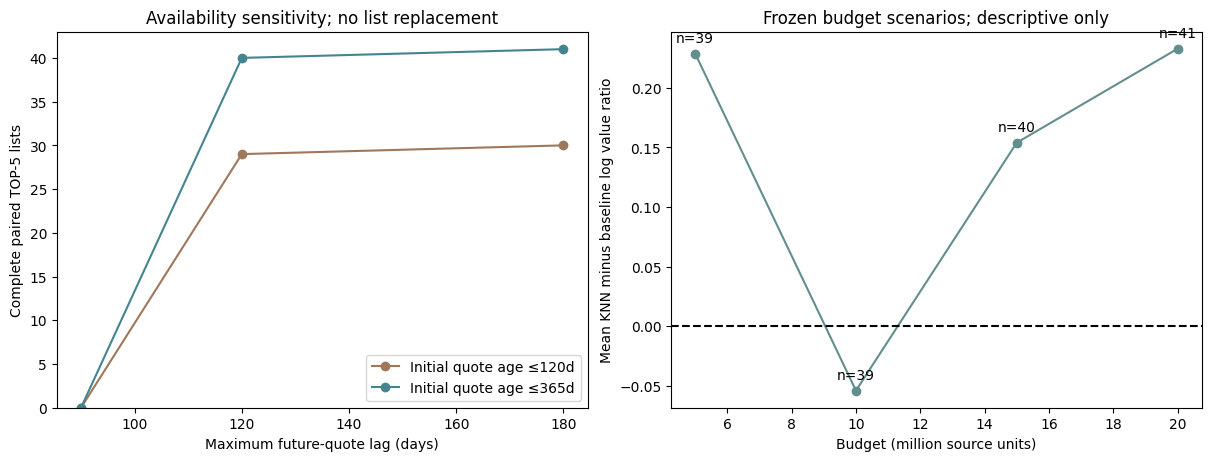

In [9]:
sensitivity=[]
for lag in [90,120,180]:
    follow=dated_value_outcomes(data,history,cutoff=CUTOFF,max_lag_days=lag)
    for base_age in [120,365]:
        for budget in protocol["budget_sensitivity"]:
            fixed=lists.loc[lists.budget.eq(budget)&lists.primary_reference]
            check=paired_list_outcomes(fixed,follow,top_k=TOP_K,max_baseline_age_days=base_age)
            complete=check.loc[check.complete_both]
            sensitivity.append({"future_max_lag_days":lag,"baseline_max_age_days":base_age,"budget":budget,
                                "complete_pairs":len(complete),"total_primary_references":len(check),
                                "mean_knn_minus_baseline_log_ratio":float(complete.knn_minus_baseline_log_ratio.mean()) if len(complete) else np.nan,
                                "fraction_pairs_knn_higher":float(complete.knn_minus_baseline_log_ratio.gt(0).mean()) if len(complete) else np.nan})
sensitivity=pd.DataFrame(sensitivity);sensitivity.to_csv(REPORT/"future_protocol_sensitivity.csv",index=False)
display(sensitivity.loc[sensitivity.budget.eq(BUDGET)])
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
for age,color in [(120,"#9f785b"),(365,"#44848f")]:
    s=sensitivity.loc[sensitivity.budget.eq(BUDGET)&sensitivity.baseline_max_age_days.eq(age)]
    axes[0].plot(s.future_max_lag_days,s.complete_pairs,"o-",label=f"Initial quote age ≤{age}d",color=color)
axes[0].set(xlabel="Maximum future-quote lag (days)",ylabel="Complete paired TOP-5 lists",ylim=(0,43),title="Availability sensitivity; no list replacement");axes[0].legend()
s=sensitivity.loc[sensitivity.future_max_lag_days.eq(120)&sensitivity.baseline_max_age_days.eq(365)]
axes[1].plot(s.budget/1e6,s.mean_knn_minus_baseline_log_ratio,"o-",color="#638e8e")
axes[1].axhline(0,color="black",ls="--")
for _,r in s.iterrows():
    if np.isfinite(r.mean_knn_minus_baseline_log_ratio):axes[1].annotate(f"n={int(r.complete_pairs)}",(r.budget/1e6,r.mean_knn_minus_baseline_log_ratio),xytext=(0,8),textcoords="offset points",ha="center")
axes[1].set(xlabel="Budget (million source units)",ylabel="Mean KNN minus baseline log value ratio",title="Frozen budget scenarios; descriptive only")
show(fig,"06_protocol_and_budget_sensitivity")


## 9. Ограничения практической интерпретации

- Сходство — критерий оптимизации KNN, не внешнее доказательство полезности. Step 6 также показал, что по скрытым блокам у дорогих референсов преимущество неубедительно; здесь не переопределяем скрытые атрибуты как реальные будущие матчи.
- Изменение recorded market value после отбора — внешний по времени proxy. Возраст, лига, первоначальный уровень, игровое время, травмы, экономический цикл и состав списков могут объяснять различия. Случайного назначения «трансфера» нет.
- Отношение будущей стоимости к исходной математически зависит от знаменателя; подбор дешёвых игроков и mean reversion могут создавать привлекательные относительные изменения. Проверяем одновременно исходную цену и различия уровня.
- Повторные кандидаты, слабое покрытие исходов и давность цен ограничивают сравнение. Нельзя трактовать число query-слотов как объём независимой экономической выборки.
- Архив ретроспективный; исторические effective dates не доказывают точное время публикации/пересмотра. Возможны revision и survivorship bias. Test ранее изучался в EDA; результат исследовательский, не подтверждающий.
- Нет доказательства улучшения выступлений, прибыли клуба или причинного превосходства трансферной политики. Следующая независимая проверка требует нового периода/набора игроков и спортивных outcomes с датами матчей, league/minutes adjustment и учётом стоимости сделки.


In [10]:
assert sha(OUT/"frozen_recommendations_all_budgets.csv")==list_hash
checks={"source_verified":sha(source)==ms["input_sha256"],"bundles_verified":sha(mp)==ms["model_sha256"] and sha(vp)==vs["model_sha256"],
        "no_future_in_selection":bool(main.market_value_date.le(CUTOFF).all() and main.fifa_update_date.eq(CUTOFF).all()),
        "disjoint_queries_gallery":not bool(set(test.fifa_id)&set(model.gallery_.fifa_id)),
        "same_eligible_pool":bool(all(a.eligible_ids_sha256.eq(expected_pool_hashes[int(a.budget.iloc[0])]).all() for a in audit_parts)),
        "recommendations_unchanged_after_future_join":sha(OUT/"frozen_recommendations_all_budgets.csv")==list_hash,
        "valid_followup_dates":bool(observed.future_value_date.between(pd.Timestamp("2023-05-29"),pd.Timestamp("2023-09-26")).all()),
        "unavailable_returns_missing":bool(outcomes.loc[~outcomes.outcome_observed,"log_value_ratio"].isna().all()),
        "regression_metrics_reproduced":bool(np.isclose(reg_metrics.loc["Random Forest log","R2"],vs["test_metrics"]["Random Forest log"]["R2_raw"]))}
assert all(checks.values()),checks
primary_result=future_results.set_index("population").loc["primary_expensive"]
delta_mean=float(primary_result.mean_knn_minus_baseline_log_ratio)
direction="выше" if np.isfinite(delta_mean) and delta_mean>0 else "ниже" if np.isfinite(delta_mean) else "не определён"
future_interpretation=(f"Полных пар {int(primary_result.complete_pairs)}/41; средняя разница KNN minus baseline log-ratio={delta_mean:.4f}. "
                       f"Наблюдаемый показатель KNN {direction}, но причинная/спортивная эффективность и обобщаемое превосходство не установлены.")
ten_million=sensitivity.loc[sensitivity.future_max_lag_days.eq(120)&sensitivity.baseline_max_age_days.eq(365)&sensitivity.budget.eq(10_000_000)].iloc[0]
strict_window=sensitivity.loc[sensitivity.future_max_lag_days.eq(90)&sensitivity.baseline_max_age_days.eq(365)&sensitivity.budget.eq(BUDGET)].iloc[0]
robustness_note=(f"При бюджете 10 млн: разница log-ratio={ten_million.mean_knn_minus_baseline_log_ratio:.4f}, полных пар {int(ten_million.complete_pairs)}. "
                 f"При основном бюджете и окне будущей оценки 90 дней: полных пар {int(strict_window.complete_pairs)}. "
                 "Знак результата зависит от бюджета; доступность зависит от календаря переоценок.")
display(Markdown(f"**Вывод о практической ценности:** {future_interpretation}"))
display(Markdown(robustness_note))
summary={"protocol":protocol,"history_audit":history_audit,"cluster_metrics":clusters,
         "regression_metrics":reg_metrics.to_dict(orient="index"),"noise_primary_overlap_sigma1":float(noise.loc[noise.primary_reference&noise.sigma.eq(1),"overlap_at5"].mean()),
         "future_results":future_results.to_dict(orient="records"),"future_coverage":coverage_table.to_dict(orient="records"),
         "future_interpretation":future_interpretation,"sensitivity_interpretation":robustness_note,"validation":{k:bool(v) for k,v in checks.items()},"figures":figures,
         "inputs_sha256":{"feature_table":sha(source),"knn_bundle":sha(mp),"rf_bundle":sha(vp)},
         "conclusion":"Descriptive selection trade-offs and subsequent recorded-value outcomes; no causal transfer or sporting-success proof."}
def finite_json(obj):
    if isinstance(obj,dict):return {k:finite_json(v) for k,v in obj.items()}
    if isinstance(obj,list):return [finite_json(v) for v in obj]
    if isinstance(obj,float) and not np.isfinite(obj):return None
    return obj
(REPORT/"evaluation_summary.json").write_text(json.dumps(finite_json(summary),ensure_ascii=False,indent=2,allow_nan=False),encoding="utf-8")
(OUT/"evaluation_manifest.json").write_text(json.dumps({"inputs":summary["inputs_sha256"],"outputs":{p.name:sha(p) for p in sorted(OUT.iterdir()) if p.is_file() and p.name!="evaluation_manifest.json"}},indent=2),encoding="utf-8")
lines=["# Step 7 — Model Evaluation & Validation","",f"Срез {CUTOFF}; 2308 train-кандидатов, 578 test-референсов, основная группа 41 дорогой игрок. Бюджет 15 млн исходных единиц (EUR — допущение), возраст ≤30, TOP-5.",
       "", "## Проверка моделей","",f"K-Means k={model.n_clusters}: test silhouette={sil_test:.3f}; медианный refit ARI={np.median(stability):.3f}. Группы устойчивы, но слабо разделены; футбольные роли не доказаны.",
       "",f"KNN: средний overlap@5 при query-noise σ=1 у 41 дорогого референса={summary['noise_primary_overlap_sigma1']:.1%}. Геометрия использует только 18 игровых признаков; сравнение с baseline на тех же допустимых ID. Преимущество cosine — внутренний критерий, не независимое качество трансфера.",
       "",f"RF: test MAE={reg_metrics.loc['Random Forest log','MAE']:,.0f}, RMSE={reg_metrics.loc['Random Forest log','RMSE']:,.0f}, R²={reg_metrics.loc['Random Forest log','R2']:.3f}. Ridge лучше в исходной шкале; преимущество RF по log-MAE неубедительно по прежнему paired CI.",
       "", "## Последующая стоимость","",f"Архив содержит {history_audit['rows']:,} датированных записей, диапазон {history_audit['min_date']} — {history_audit['max_date']}. Outcome: последняя стоимость ≤26.09.2023, лаг ≤120 дней; zero/conflicting/missing недоступны.",
       "",future_interpretation,
       "",f"Основная группа: baseline — {int(coverage_table.iloc[0].unique_candidates)} уникальных кандидатов, KNN — {int(coverage_table.iloc[1].unique_candidates)}, из них с исходом {int(coverage_table.iloc[1].observed_unique_candidates)}. Это существенно меньше числа слотов; независимость запросов отсутствует.",
       "",robustness_note,
       "", "Списки зафиксированы до чтения истории; состав не меняется ради доступности исходов. Sensitivity 90/120/180 дней, свежесть исходной оценки 120/365 дней, бюджеты 5/10/15/20 млн сохранены полностью. Повторное использование кандидатов запрещает трактовать слоты/запросы как независимые экономические наблюдения; независимые query-slot p-values/CI не рассчитывались.",
       "", "## Практические границы","", "Результат — воспроизводимое сравнение подбора и ретроспективный backtest записанной стоимости. Не доказаны прибыль, спортивная эффективность или причинное превосходство политики трансферов. Различия возраста/лиги/уровня, denominator coupling, устаревание оценок, missingness, revisions и survivorship bias остаются. Фактический интервал между переоценками отличается от 365 дней; изменения не annualized returns. Test уже исследовался в EDA. Нужны независимый период и спортивные outcomes с датами матчей.",
       "", "## Артефакты","", "Notebook: `notebooks/07_model_evaluation.ipynb`. Протокол, метрики, sensitivity и шесть PNG/SVG: `reports/evaluation/`. Замороженные списки, side-by-side Крооса, per-player future outcomes, noise trials и hashed manifest: gitignored `data/processed/evaluation/`. Модуль датированного присоединения и парного анализа: `src/evaluation.py`; тесты: `tests/test_evaluation.py`. Регрессионный notebook `07_market_value_prediction.ipynb` сохранён отдельно."]
(ROOT/"docs/model_evaluation.md").write_text("\n".join(lines)+"\n",encoding="utf-8")
display(pd.Series(checks,name="passed"))


**Вывод о практической ценности:** Полных пар 40/41; средняя разница KNN minus baseline log-ratio=0.1539. Наблюдаемый показатель KNN выше, но причинная/спортивная эффективность и обобщаемое превосходство не установлены.

При бюджете 10 млн: разница log-ratio=-0.0541, полных пар 39. При основном бюджете и окне будущей оценки 90 дней: полных пар 0. Знак результата зависит от бюджета; доступность зависит от календаря переоценок.

source_verified                                True
bundles_verified                               True
no_future_in_selection                         True
disjoint_queries_gallery                       True
same_eligible_pool                             True
recommendations_unchanged_after_future_join    True
valid_followup_dates                           True
unavailable_returns_missing                    True
regression_metrics_reproduced                  True
Name: passed, dtype: bool